# A café: counting people

Not every simulation is a signal. Here the samples are seconds and the
values are people: customers arrive at random, wait, are served by one of a
few baristas, or leave when the queue is too long. Random sources decide
who arrives and who is done; one `FuncSingle` with named state keeps the
count in whole people. A long run with one barista is checked against the
exact distribution of a Markov chain.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import sigline as sl

## 1. The model

Each second, every busy barista finishes with probability $\mu$ (two
minutes on average), a customer arrives with probability $\lambda/3600$
for $\lambda$ customers per hour, a newcomer leaves if ten already wait,
and free baristas take the next in line. `RandomPulses` make the random
events; the café is a function of one second, written with `if` and
integers.

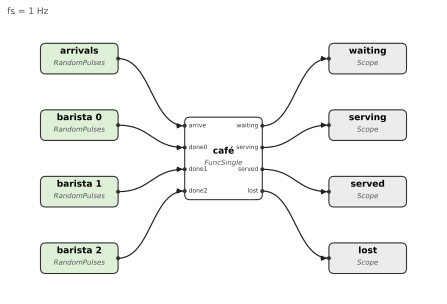

In [2]:
def cafe(arrive, done0, done1, done2, s, baristas=2, max_waiting=10):
    waiting, serving, served, lost = s.waiting, s.serving, s.served, s.lost
    finished = 0
    for k, done in enumerate((done0, done1, done2)):
        if k < serving and done > 0:
            finished += 1
    serving -= finished
    served += finished
    if arrive > 0:
        if waiting < max_waiting:
            waiting += 1
        else:
            lost += 1
    while serving < baristas and waiting > 0:
        serving, waiting = serving + 1, waiting - 1
    s = type(s)(waiting, serving, served, lost)
    return (waiting, serving, served, lost), s


def build(baristas, per_hour, max_waiting=10, seed=1):
    arrivals = sl.RandomPulses(p=per_hour / 3600, seed=seed, name="arrivals")
    shop = sl.FuncSingle(
        cafe,
        state=sl.state(waiting=0, serving=0, served=0, lost=0),
        outputs=("waiting", "serving", "served", "lost"),
        params={"baristas": baristas, "max_waiting": max_waiting},
        name="café",
    )
    arrivals >> shop["arrive"]
    for k in range(3):
        (
            sl.RandomPulses(p=1 / 120, seed=seed + 10 + k, name=f"barista {k}")
            >> shop[f"done{k}"]
        )
    scopes = {k: sl.Scope(k) for k in shop.outputs}
    for k, sc in scopes.items():
        shop[k] >> sc
    return sl.Diagram(*scopes.values(), fs=1.0), arrivals, scopes


d, arrivals, scopes = build(2, 40.0)
d

## 2. Against theory: one barista

With one barista and no limit, the number $n$ in the café is a Markov
chain: from $n \ge 1$ down with $q(1-p)$, up with $p(1-q)$, for
$p = \lambda/3600$, $q = \mu$; from 0 up with $p$. Thirty simulated days at
20 per hour should match `MarkovChain(P).stationary()` within the
statistical error, which the spread of the daily means gives: successive
seconds are strongly correlated.

mean people: simulated 1.896 ± 0.074, theory 1.989


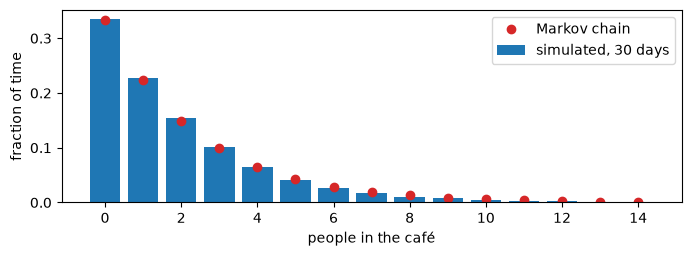

In [3]:
p, q, N = 20 / 3600, 1 / 120, 80
P = np.zeros((N, N))
P[0, :2] = 1 - p, p
for n in range(1, N - 1):
    P[n, n - 1], P[n, n + 1] = q * (1 - p), p * (1 - q)
    P[n, n] = 1 - P[n, n - 1] - P[n, n + 1]
P[N - 1, N - 2 :] = q * (1 - p), 1 - q * (1 - p)
pi = sl.MarkovChain(P).stationary()

d, _, scopes = build(1, 20.0, max_waiting=10**6, seed=7)
d.run(30 * 86400, chunk=86400)
people = scopes["waiting"].data + scopes["serving"].data
se = people.reshape(30, -1).mean(axis=1).std(ddof=1) / np.sqrt(30)
L = np.sum(np.arange(N) * pi)
print(f"mean people: simulated {people.mean():.3f} ± {se:.3f}, theory {L:.3f}")

counts = np.bincount(people.astype(int), minlength=N)[:15] / len(people)
fig, ax = plt.subplots(figsize=(8, 2.5))
ax.bar(range(15), counts, label="simulated, 30 days")
ax.plot(range(15), pi[:15], "o", c="C3", label="Markov chain")
ax.set(xlabel="people in the café", ylabel="fraction of time")
ax.legend()
plt.show()

## 3. A day, and how many baristas

Arrivals follow the day: a breakfast rush, a quiet morning, lunch, a quiet
afternoon. Each period is one more `run` with a changed arrival
probability; everything else continues. Twenty days per staffing level, a
`for` loop over seeds inside one over staff; Little's law turns people
waiting into minutes waited.

In [4]:
day = [((7.0, 8.0), 30.0), ((8.0, 9.5), 75.0), ((9.5, 12.0), 25.0),
       ((12.0, 13.5), 60.0), ((13.5, 19.0), 20.0)]  # fmt: skip


def run_day(baristas, seed):
    d, arrivals, scopes = build(baristas, 0.0, seed=seed)
    for (start, end), rate in day:
        arrivals.p_start = rate / 3600
        d.run((end - start) * 3600, chunk=900)
    return d, scopes


print("baristas   served   lost   minutes waited")
for baristas in (1, 2, 3):
    days = [run_day(baristas, seed)[1] for seed in range(20)]
    served = np.mean([s["served"].data[-1] for s in days])
    lost = np.mean([s["lost"].data[-1] for s in days])
    waiting = np.mean([s["waiting"].data.mean() for s in days])
    minutes = waiting / (served / 43200) / 60  # little: waiting / throughput
    print(f"{baristas:8d}   {served:6.0f}   {lost:4.0f}   {minutes:14.1f}")

baristas   served   lost   minutes waited


       1      300    107              9.6


       2      383     26              2.7


       3      407      2              0.7


## 4. Watching the rush

`d.watch` plays the breakfast rush 900 times faster than real time: 90
minutes in six seconds. Each dot is a person waiting, the squares are the
baristas' customers; crosses are people who left.

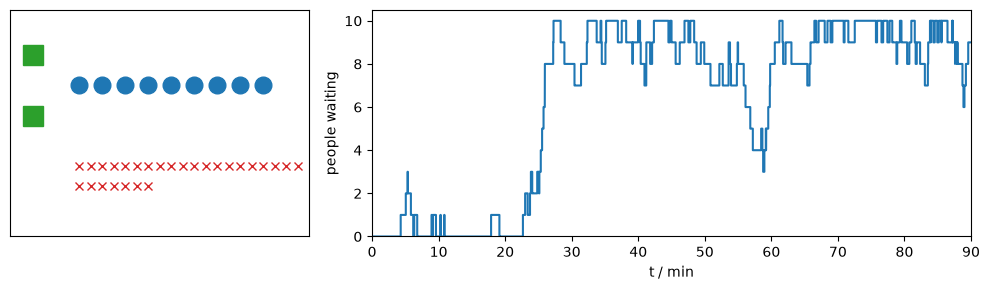

In [5]:
d, arrivals, scopes = build(2, 75.0, seed=3)


def draw(fig):
    a1, a2 = fig.subplots(1, 2, gridspec_kw={"width_ratios": [1, 2]})
    (queue,) = a1.plot([], [], "o", ms=12, c="C0")
    (counter,) = a1.plot([], [], "s", ms=14, c="C2")
    (gone,) = a1.plot([], [], "x", c="C3")
    a1.set(xlim=(-3, 10), ylim=(-3, 1.5), xticks=[], yticks=[])
    (line,) = a2.step([], [], where="post")
    a2.set(xlim=(0, 90), ylim=(0, 10.5), xlabel="t / min", ylabel="people waiting")
    fig.tight_layout()

    def update():
        t, waiting = scopes["waiting"].snapshot()
        if len(t):
            w, s = int(waiting[-1]), int(scopes["serving"].data[-1])
            lost = int(scopes["lost"].data[-1])
            queue.set_data(np.arange(w), np.zeros(w))
            counter.set_data([-2, -2][:s], [0.6, -0.6][:s])
            gone.set_data(
                np.arange(lost) % 20 * 0.5, -1.6 - np.arange(lost) // 20 * 0.4
            )
            line.set_data(t / 60, waiting)
        return queue, counter, gone, line

    return update


d.watch(1.5 * 3600, draw, speed=900, figsize=(10, 3))

## Summary

- Discrete events fit the same blocks: random sources for arrivals and
  service, a `FuncSingle` with named integer state for the bookkeeping.
- The simulation matches the Markov chain's stationary distribution.
- Schedules are runs with changed parameters; staffing is a `for` loop;
  `d.watch` plays it live, faster than real time.